Dynamic Pricing for Ride-Hailing: Analysis and Modelling

Goal: understand what drives ride fares and benchmark models (Linear Regression, Random Forest, XGBoost) that predict fares from demand, supply and ride features. All costs are in ₹ (the original Kaggle data has no currency).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('dynamic_pricing.csv')

In [3]:
df.shape

(1000, 10)

# Analyzing dataframe

In [4]:
df.head()

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422


In [5]:
df.dtypes

,0
Number_of_Riders,int64
Number_of_Drivers,int64
Location_Category,object
Customer_Loyalty_Status,object
Number_of_Past_Rides,int64
Average_Ratings,float64
Time_of_Booking,object
Vehicle_Type,object
Expected_Ride_Duration,int64
Historical_Cost_of_Ride,float64


One quick observation - number of riders shows total customer demand for rides
number of drivers shows available supply to fulfill them

In [59]:
df.tail()

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride,Demand_to_Supply_Ratio,Ratio_Bucket,Cost_Per_Minute,Loyalty_Decile,Log_Historical_Cost
995,33,23,Urban,Gold,24,4.21,Morning,Premium,11,91.389526,1.434783,"(1.1, 1.54]",8.308139,3,4.526014
996,84,29,Urban,Regular,92,4.55,Morning,Premium,94,424.155987,2.896552,"(2.75, 4.31]",4.512298,10,6.052456
997,44,6,Suburban,Gold,80,4.13,Night,Premium,40,157.364830,7.333333,"(4.31, 17.6]",3.934121,8,5.064901
998,53,27,Suburban,Regular,78,3.63,Night,Premium,58,279.095048,1.962963,"(1.54, 2.03]",4.811984,8,5.635129
999,78,63,Rural,Gold,14,4.21,Afternoon,Economy,147,655.065106,1.238095,"(1.1, 1.54]",4.456225,2,6.486260


In [7]:
df.isna().sum() # no null values

,0
Number_of_Riders,0
Number_of_Drivers,0
Location_Category,0
Customer_Loyalty_Status,0
Number_of_Past_Rides,0
Average_Ratings,0
Time_of_Booking,0
Vehicle_Type,0
Expected_Ride_Duration,0
Historical_Cost_of_Ride,0


In [8]:
df.describe()

,Number_of_Riders,Number_of_Drivers,Number_of_Past_Rides,Average_Ratings,Expected_Ride_Duration,Historical_Cost_of_Ride
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,60.372000,27.076000,50.031000,4.257220,99.58800,372.502623
std,23.701506,19.068346,29.313774,0.435781,49.16545,187.158756
min,20.000000,5.000000,0.000000,3.500000,10.00000,25.993449
25%,40.000000,11.000000,25.000000,3.870000,59.75000,221.365202
50%,60.000000,22.000000,51.000000,4.270000,102.00000,362.019426
75%,81.000000,38.000000,75.000000,4.632500,143.00000,510.497504
max,100.000000,89.000000,100.000000,5.000000,180.00000,836.116419


In [9]:
df.describe(include='all')

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
count,1000.000000,1000.000000,1000,1000,1000.000000,1000.000000,1000,1000,1000.00000,1000.000000
unique,NaN,NaN,3,3,NaN,NaN,4,2,NaN,NaN
top,NaN,NaN,Urban,Silver,NaN,NaN,Night,Premium,NaN,NaN
freq,NaN,NaN,346,367,NaN,NaN,276,522,NaN,NaN
mean,60.372000,27.076000,NaN,NaN,50.031000,4.257220,NaN,NaN,99.58800,372.502623
std,23.701506,19.068346,NaN,NaN,29.313774,0.435781,NaN,NaN,49.16545,187.158756
min,20.000000,5.000000,NaN,NaN,0.000000,3.500000,NaN,NaN,10.00000,25.993449
25%,40.000000,11.000000,NaN,NaN,25.000000,3.870000,NaN,NaN,59.75000,221.365202
50%,60.000000,22.000000,NaN,NaN,51.000000,4.270000,NaN,NaN,102.00000,362.019426
75%,81.000000,38.000000,NaN,NaN,75.000000,4.632500,NaN,NaN,143.00000,510.497504


In [10]:
df.dtypes.value_counts()

,count
int64,4
object,4
float64,2


In [11]:
df["Historical_Cost_of_Ride"].describe()

,Historical_Cost_of_Ride
count,1000.000000
mean,372.502623
std,187.158756
min,25.993449
25%,221.365202
50%,362.019426
75%,510.497504
max,836.116419


# Basic data exploration and categorical trends

In [12]:
df.groupby('Location_Category')[['Number_of_Riders', 'Number_of_Drivers']].mean()

,Number_of_Riders,Number_of_Drivers
Location_Category,,
Rural,57.957831,24.849398
Suburban,62.285714,28.506211
Urban,60.907514,27.881503


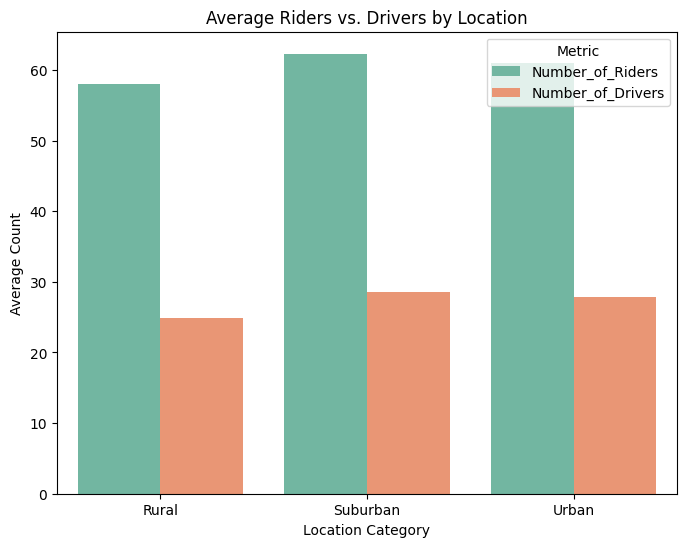

In [13]:
# 1. Save the grouped data and reset the index so 'Location_Category' becomes a column
grouped_df = df.groupby('Location_Category')[['Number_of_Riders', 'Number_of_Drivers']].mean().reset_index()

# 2. Melt the dataframe to format it for Seaborn
melted_df = grouped_df.melt(id_vars='Location_Category',
                            value_vars=['Number_of_Riders', 'Number_of_Drivers'],
                            var_name='Metric',
                            value_name='Average_Count')

# 3. Plot the data using a grouped barplot
plt.figure(figsize=(8, 6))
sns.barplot(data=melted_df, x='Location_Category', y='Average_Count', hue='Metric', palette='Set2')

plt.title('Average Riders vs. Drivers by Location')
plt.ylabel('Average Count')
plt.xlabel('Location Category')
plt.show()

Observation - Each location is having a very big shortage. If we see Suburban, 62.28 are Riders and 28.5 are the Drivers and what we see is it cannot be fulfilled.

In [14]:
pd.crosstab(df['Location_Category'], df['Customer_Loyalty_Status'])

Customer_Loyalty_Status,Gold,Regular,Silver
Location_Category,,,
Rural,112,103,117
Suburban,92,107,123
Urban,109,110,127


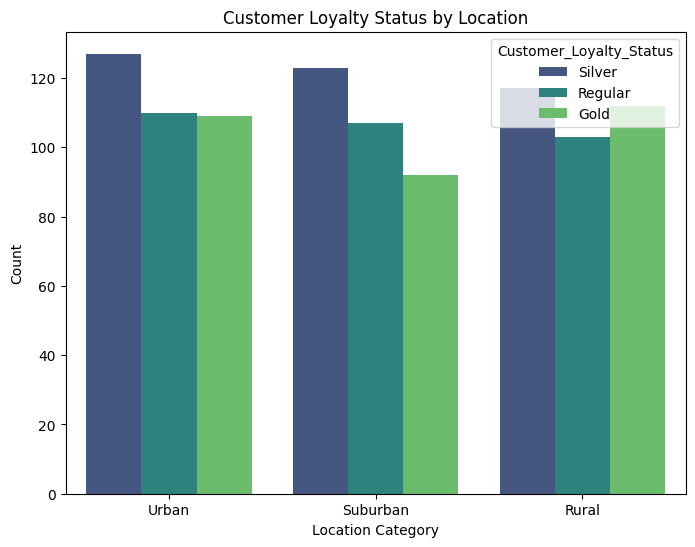

In [15]:
plt.figure(figsize=(8, 6))

# countplot automatically groups by x and separates by hue
sns.countplot(data=df,
              x='Location_Category',
              hue='Customer_Loyalty_Status',
              palette='viridis')

plt.title('Customer Loyalty Status by Location')
plt.ylabel('Count')
plt.xlabel('Location Category')
plt.show()

Observation - Rural members are having higher number of Gold members than urban and suburban.
Urban areas are having higher number of silver and regular loyalty.

In [16]:
df.groupby('Location_Category')['Average_Ratings'].mean()

,Average_Ratings
Location_Category,
Rural,4.255723
Suburban,4.250062
Urban,4.265318


/tmp/ipykernel_4441/3266605686.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_ratings, x='Location_Category', y='Average_Ratings', palette='pastel')


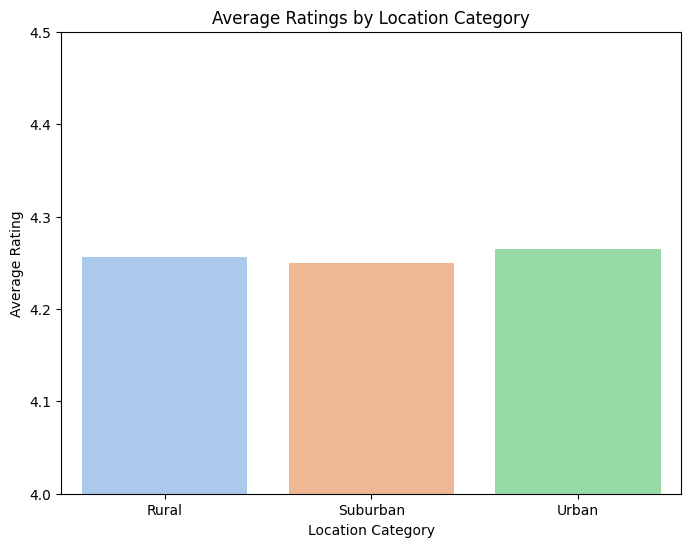

In [17]:
# 1. Group the data and reset the index so Seaborn can read the columns
avg_ratings = df.groupby('Location_Category')['Average_Ratings'].mean().reset_index()

# 2. Create the barplot
plt.figure(figsize=(8, 6))
sns.barplot(data=avg_ratings, x='Location_Category', y='Average_Ratings', palette='pastel')

# 3. Restrict the y-axis limits (optional but recommended)
# Since all average ratings are extremely close (around 4.25 - 4.26),
# zooming the y-axis makes the tiny differences visible.
plt.ylim(4.0, 4.5)

plt.title('Average Ratings by Location Category')
plt.ylabel('Average Rating')
plt.xlabel('Location Category')
plt.show()

The average rating is almost identical across all 3 areas.

In [18]:
df.groupby(['Location_Category', 'Time_of_Booking', 'Vehicle_Type']).size().unstack(fill_value=0)

Vehicle_Type                       Economy  Premium
Location_Category Time_of_Booking                  
Rural             Afternoon             37       46
                  Evening               38       45
                  Morning               38       43
                  Night                 40       45
Suburban          Afternoon             46       36
                  Evening               27       44
                  Morning               45       42
                  Night                 40       42
Urban             Afternoon             40       42
                  Evening               33       44
                  Morning               38       40
                  Night                 56       53

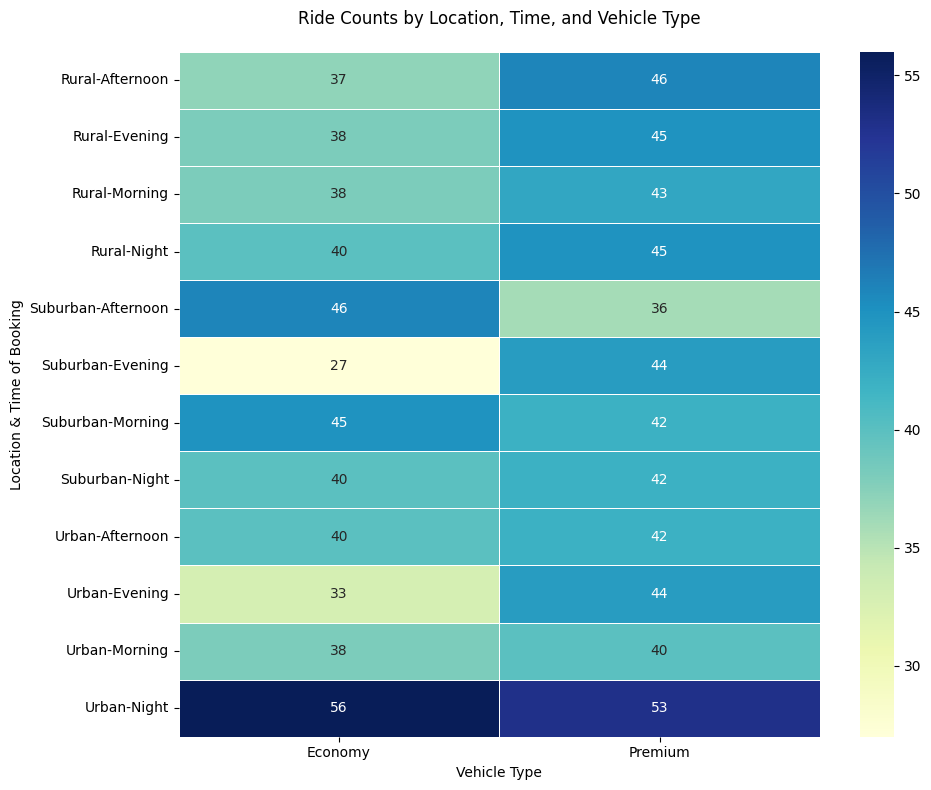

In [19]:
grouped_data = df.groupby(['Location_Category', 'Time_of_Booking', 'Vehicle_Type']).size().unstack(fill_value=0)

# 2. Set up the figure size
plt.figure(figsize=(10, 8))

# 3. Create the Seaborn heatmap
sns.heatmap(
    grouped_data,
    annot=True,        # Prints the actual numbers inside the boxes
    fmt="d",           # Ensures numbers are formatted as integers
    cmap="YlGnBu",     # Uses a Yellow-Green-Blue color scale
    linewidths=.5      # Adds a small border between boxes for readability
)

# 4. Add labels
plt.title('Ride Counts by Location, Time, and Vehicle Type', pad=20)
plt.ylabel('Location & Time of Booking')
plt.xlabel('Vehicle Type')

plt.tight_layout()
plt.show()

Observation - At night in urban areas, we have 56 economy and 53 premium vehicles

In [20]:
df.groupby('Location_Category')['Number_of_Past_Rides'].mean()

,Number_of_Past_Rides
Location_Category,
Rural,47.713855
Suburban,51.338509
Urban,51.037572


/tmp/ipykernel_4441/2456619322.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_rides, x='Location_Category', y='Number_of_Past_Rides', palette='muted')


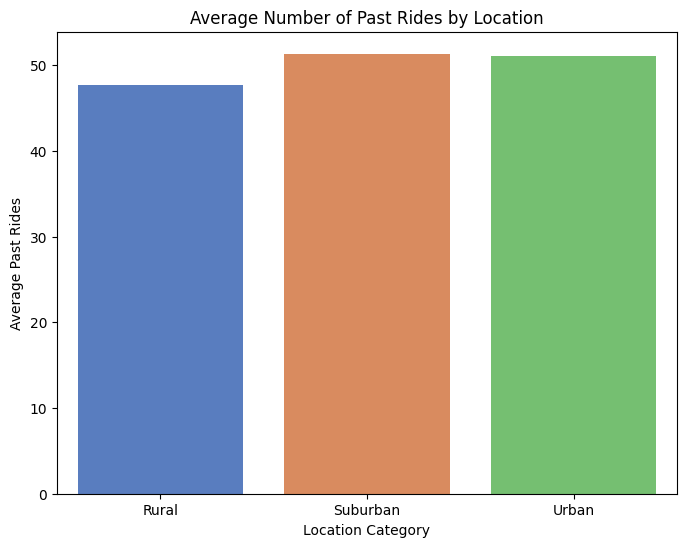

In [21]:
avg_rides = df.groupby('Location_Category')['Number_of_Past_Rides'].mean().reset_index()

# 2. Create the barplot
plt.figure(figsize=(8, 6))
sns.barplot(data=avg_rides, x='Location_Category', y='Number_of_Past_Rides', palette='muted')

# 3. Add labels and title
plt.title('Average Number of Past Rides by Location')
plt.ylabel('Average Past Rides')
plt.xlabel('Location Category')

plt.show()

Observation - Suburban and urban areas have almost same number of past rides

In [22]:
df.groupby(['Location_Category', 'Customer_Loyalty_Status'])['Average_Ratings'].mean().unstack()

Customer_Loyalty_Status,Gold,Regular,Silver
Location_Category,,,
Rural,4.183393,4.296893,4.288718
Suburban,4.230543,4.222523,4.288618
Urban,4.245596,4.250364,4.295197


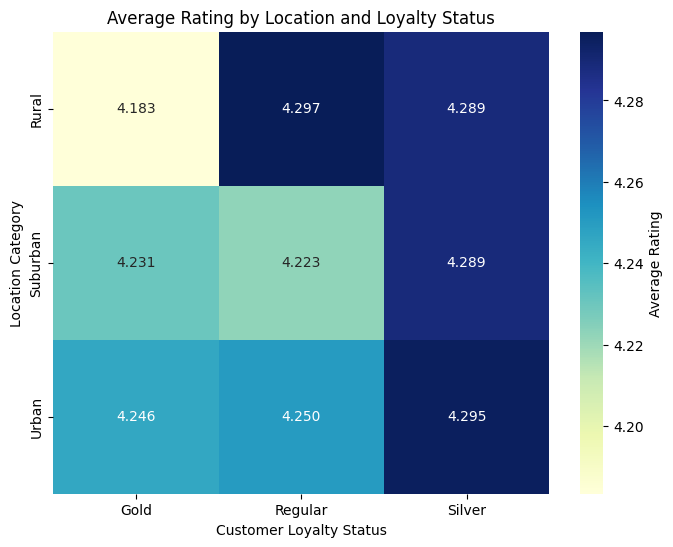

In [23]:
rating_matrix = df.groupby(['Location_Category', 'Customer_Loyalty_Status'])['Average_Ratings'].mean().unstack()

# 2. Plot the matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    rating_matrix,
    annot=True,       # Show the actual rating numbers
    fmt=".3f",        # Format numbers to 3 decimal places
    cmap="YlGnBu",
    cbar_kws={'label': 'Average Rating'}
)

plt.title('Average Rating by Location and Loyalty Status')
plt.ylabel('Location Category')
plt.xlabel('Customer Loyalty Status')
plt.show()

"Silver" members actually give the highest average ratings across all three location categories, while "Gold" members give the lowest average ratings in Rural areas (4.18).

In [24]:
df[['Number_of_Past_Rides', 'Average_Ratings']].corr()

,Number_of_Past_Rides,Average_Ratings
Number_of_Past_Rides,1.000000,-0.064734
Average_Ratings,-0.064734,1.000000


In [25]:
# Group by the 3 categories, count them with .size(), and name the new column
df_long = df.groupby(['Location_Category', 'Time_of_Booking', 'Vehicle_Type']).size().reset_index(name='Count_of_Rides')

print(df_long)

   Location_Category Time_of_Booking Vehicle_Type  Count_of_Rides
0              Rural       Afternoon      Economy              37
1              Rural       Afternoon      Premium              46
2              Rural         Evening      Economy              38
3              Rural         Evening      Premium              45
4              Rural         Morning      Economy              38
5              Rural         Morning      Premium              43
6              Rural           Night      Economy              40
7              Rural           Night      Premium              45
8           Suburban       Afternoon      Economy              46
9           Suburban       Afternoon      Premium              36
10          Suburban         Evening      Economy              27
11          Suburban         Evening      Premium              44
12          Suburban         Morning      Economy              45
13          Suburban         Morning      Premium              42
14        

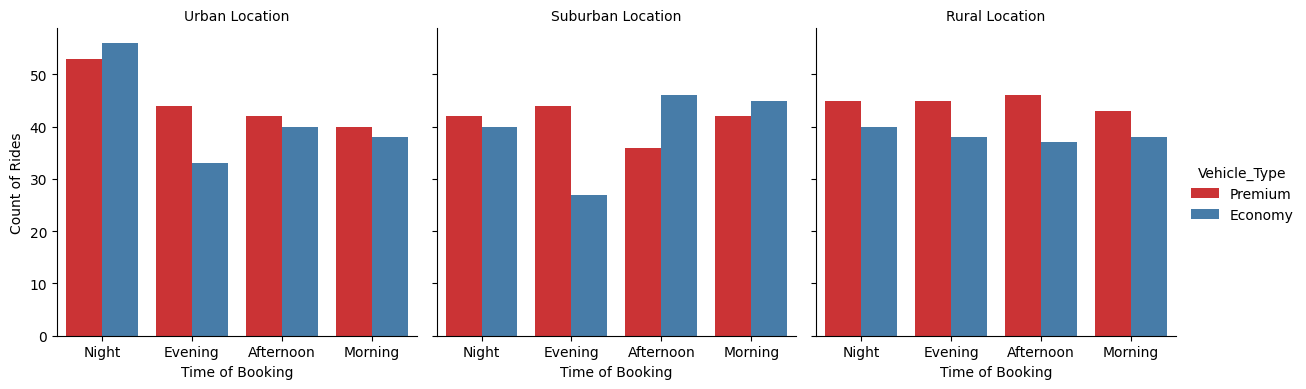

In [26]:
g = sns.catplot(
    data=df,
    x='Time_of_Booking',       # Variable 1
    hue='Vehicle_Type',        # Variable 2 (Color)
    col='Location_Category',   # Variable 3 (Splits into 3 side-by-side charts)
    kind='count',              # We are counting occurrences
    palette='Set1',
    height=4,
    aspect=1
)

g.set_axis_labels("Time of Booking", "Count of Rides")
g.set_titles("{col_name} Location")

plt.show()

Observation - if you see urban location, at evening, premium vehicles are more than economy and at night, people prefer economy more than premium.

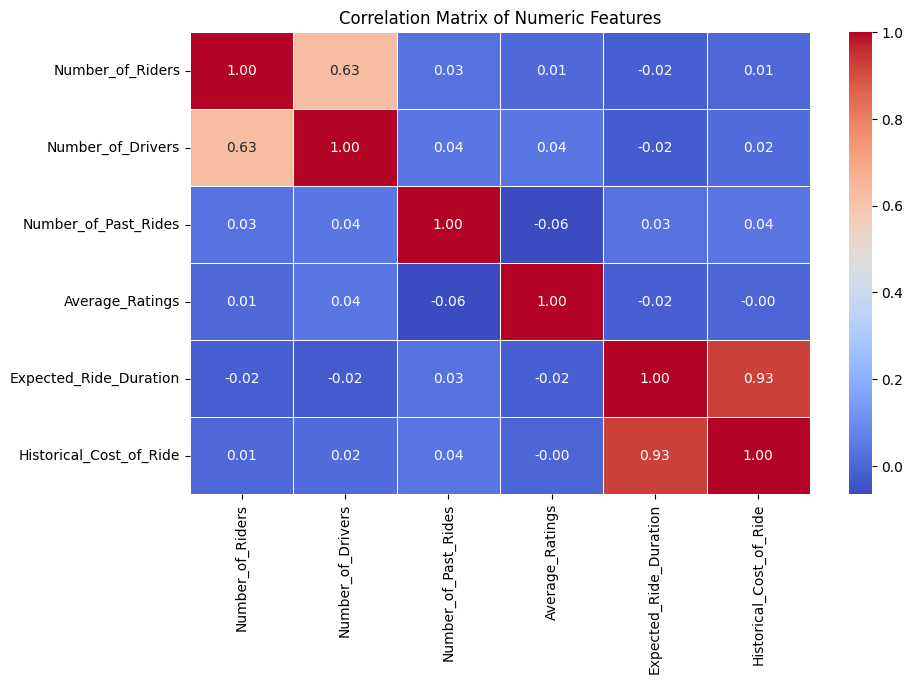

In [27]:
# Select only numeric columns for correlation
numeric_df = df.select_dtypes(include=['int64', 'float64'])
corr_matrix = numeric_df.corr()

# Plot the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Numeric Features')
plt.show()

Observation for correlation matrix -
We can see number of drivers and number of riders having a moderate correlation with each other. The supply demand ratio needs to be engineered without putting more redundant data.
Expected ride duration and historical cost of ride are having almost a positive correlation indicating base fare increases linearly with time.

/tmp/ipykernel_4441/1781596334.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Vehicle_Type', y='Historical_Cost_of_Ride', palette='Set2')


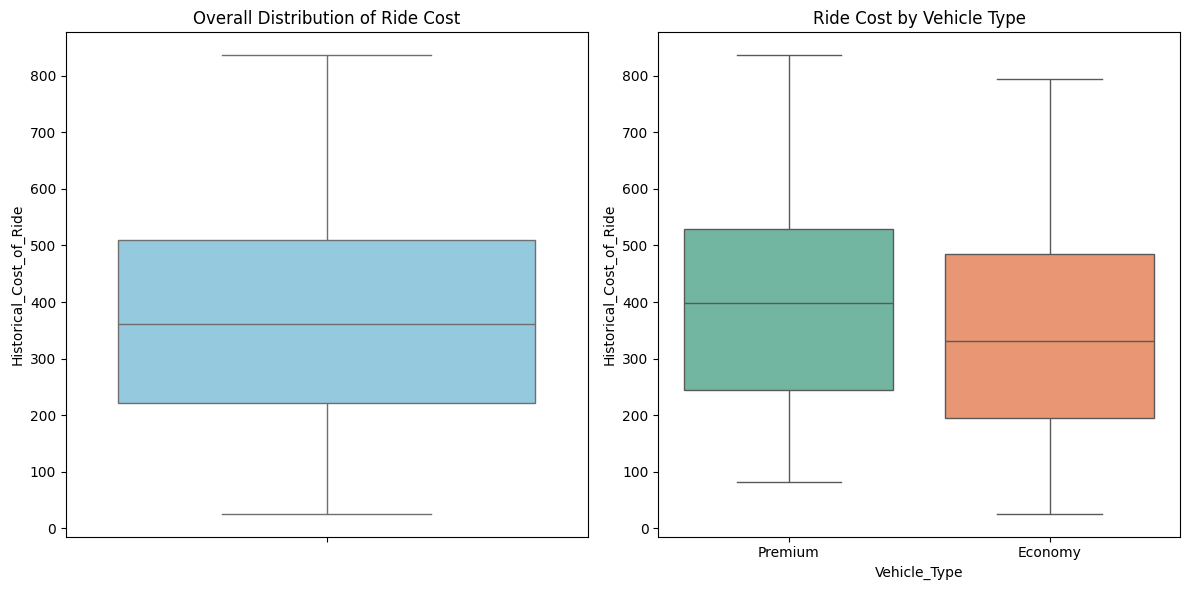

In [28]:
plt.figure(figsize=(12, 6))

# Overall distribution
plt.subplot(1, 2, 1)
sns.boxplot(data=df, y='Historical_Cost_of_Ride', color='skyblue')
plt.title('Overall Distribution of Ride Cost')

# Distribution split by Vehicle Type
plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='Vehicle_Type', y='Historical_Cost_of_Ride', palette='Set2')
plt.title('Ride Cost by Vehicle Type')

plt.tight_layout()
plt.show()

Observation - Median cost for premium vehicles is 400 and for economy, it has a range between 300-400
The price of a ride has a wide range from below 100 to more than 800 indicating that the time plays an important role here in booking a ride. We can say expected ride duration can expand this price range.

# Advanced Feature Analysis and Pricing Mechanics

/tmp/ipykernel_4441/1133711318.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tabular_summary = df.groupby('Ratio_Bucket')['Historical_Cost_of_Ride'].agg(
/tmp/ipykernel_4441/1133711318.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


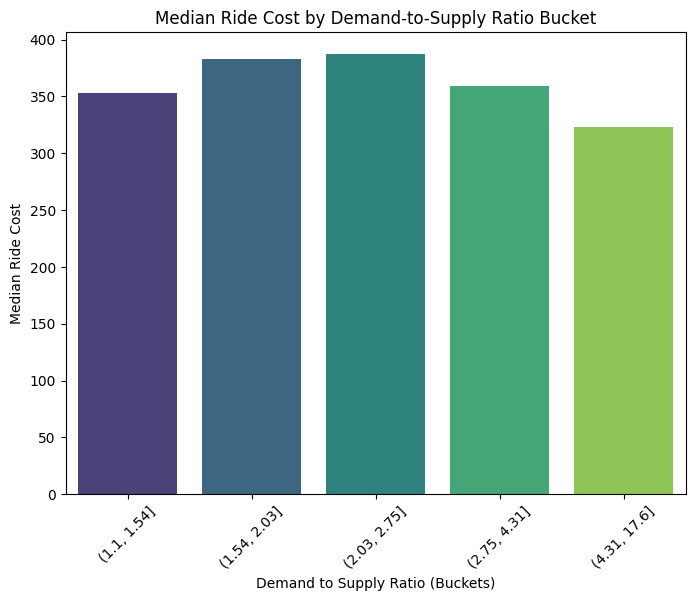

In [29]:
df['Demand_to_Supply_Ratio'] = df['Number_of_Riders'] / df['Number_of_Drivers']

# 2. Break the continuous ratio into 5 equal-sized buckets (Quintiles)
df['Ratio_Bucket'] = pd.qcut(df['Demand_to_Supply_Ratio'], q=5, precision=2)
tabular_summary = df.groupby('Ratio_Bucket')['Historical_Cost_of_Ride'].agg(
    Ride_Count='count',
    Median_Cost='median',
    Average_Cost='mean',
    Min_Cost='min',
    Max_Cost='max'
).reset_index()
plt.figure(figsize=(8, 6))
# Plot the median cost for each bucket
sns.barplot(
    data=tabular_summary,
    x='Ratio_Bucket',
    y='Median_Cost',
    palette='viridis'
)

plt.title('Median Ride Cost by Demand-to-Supply Ratio Bucket')
plt.xlabel('Demand to Supply Ratio (Buckets)')
plt.ylabel('Median Ride Cost')
plt.xticks(rotation=45)
plt.show()

In [30]:
df['Demand_to_Supply_Ratio'] = df['Number_of_Riders'] / df['Number_of_Drivers']

# 2. Break the continuous ratio into 5 equal-sized buckets (Quintiles)
df['Ratio_Bucket'] = pd.qcut(df['Demand_to_Supply_Ratio'], q=5, precision=2)

# 3. Aggregate the target variable (Ride Cost) for each bucket
tabular_summary = df.groupby('Ratio_Bucket')['Historical_Cost_of_Ride'].agg(
    Ride_Count='count',
    Median_Cost='median',
    Average_Cost='mean',
    Min_Cost='min',
    Max_Cost='max'
).reset_index()

print(tabular_summary)

   Ratio_Bucket  Ride_Count  Median_Cost  Average_Cost   Min_Cost    Max_Cost
0   (1.1, 1.54]         202   353.078651    362.878275  25.993449  814.419556
1  (1.54, 2.03]         198   383.002422    388.207563  38.235235  784.055126
2  (2.03, 2.75]         201   387.111740    393.755970  31.362081  829.534380
3  (2.75, 4.31]         199   359.128113    371.348913  35.885988  836.116419
4  (4.31, 17.6]         200   323.499418    346.463653  36.000278  806.021270


/tmp/ipykernel_4441/557549035.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tabular_summary = df.groupby('Ratio_Bucket')['Historical_Cost_of_Ride'].agg(


Observation - Pricing scale does not scale up linearly as the shortage worsens. In Bucket 4, users refuse to book premium rides, dragging overall median cost down.

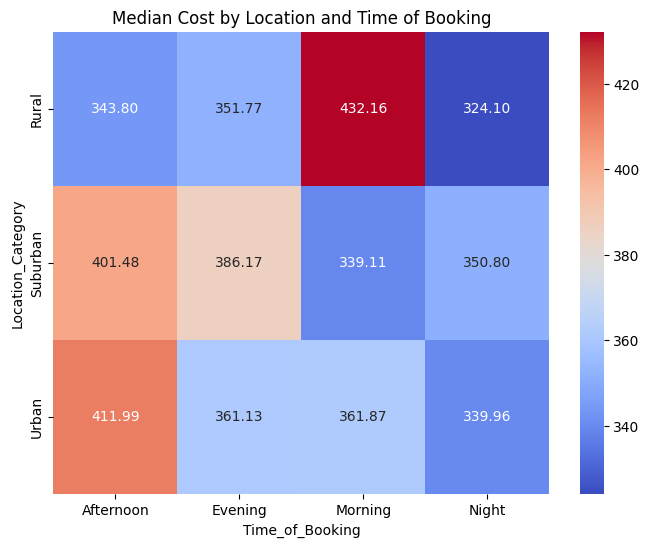

In [31]:
# Pivot table for median cost
spatio_temporal_cost = df.pivot_table(values='Historical_Cost_of_Ride',
                                      index='Location_Category',
                                      columns='Time_of_Booking',
                                      aggfunc='median')

plt.figure(figsize=(8, 6))
sns.heatmap(spatio_temporal_cost, annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Median Cost by Location and Time of Booking')
plt.show()

In [32]:
try:
    spatio_temporal_cost = df.pivot_table(
        values='Historical_Cost_of_Ride',
        index='Location_Category',
        columns='Time_of_Booking',
        aggfunc='median'
    )
    # Just print the dataframe normally
    print(spatio_temporal_cost)
except Exception as e:
    print(f"Error: {e}")

Time_of_Booking     Afternoon     Evening     Morning       Night
Location_Category                                                
Rural              343.798520  351.773619  432.162792  324.098767
Suburban           401.479872  386.169069  339.105583  350.802618
Urban              411.986533  361.132355  361.871253  339.955361


Observation - During morning in rural areas, the cost of ride is more around 432.16 whereas at night it is around 324.09

Hypothesis - Less traffic might be there during night and less time it might take to reach from origin to destination or rural users might book longer distance commutes during morning hours.

/tmp/ipykernel_4441/1263992744.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Vehicle_Type', y='Cost_Per_Minute', palette='pastel')
/tmp/ipykernel_4441/1263992744.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Customer_Loyalty_Status', y='Cost_Per_Minute', palette='pastel')


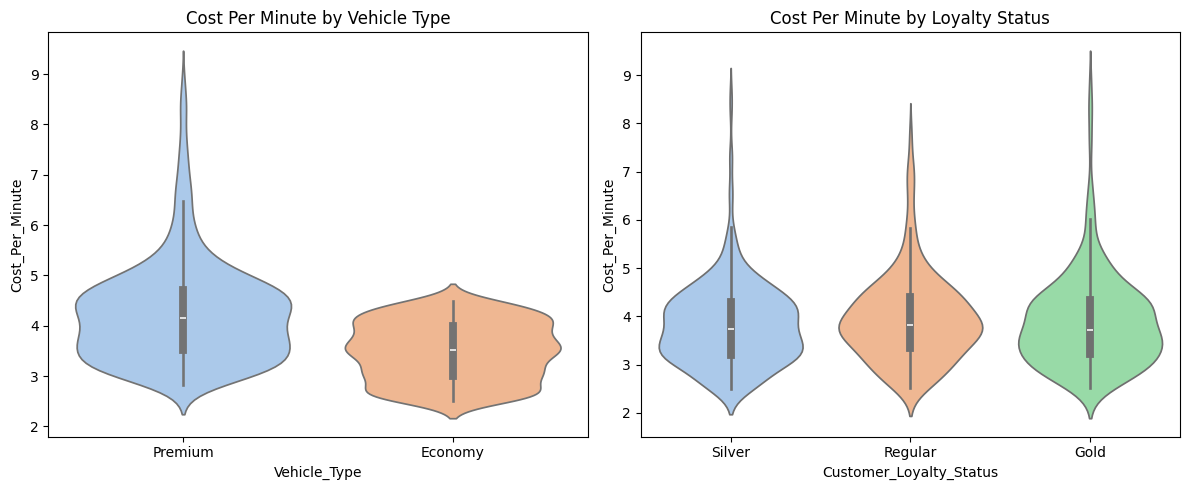

In [33]:
# Engineer Cost Per Minute
df['Cost_Per_Minute'] = df['Historical_Cost_of_Ride'] / df['Expected_Ride_Duration']

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.violinplot(data=df, x='Vehicle_Type', y='Cost_Per_Minute', palette='pastel')
plt.title('Cost Per Minute by Vehicle Type')

plt.subplot(1, 2, 2)
sns.violinplot(data=df, x='Customer_Loyalty_Status', y='Cost_Per_Minute', palette='pastel')
plt.title('Cost Per Minute by Loyalty Status')
plt.tight_layout()
plt.show()

In [34]:
# 1. Engineer Cost Per Minute
df['Cost_Per_Minute'] = df['Historical_Cost_of_Ride'] / df['Expected_Ride_Duration']

# 2. Table for Vehicle Type
vehicle_summary = df.groupby('Vehicle_Type')['Cost_Per_Minute'].agg(
    Count='count',
    Mean='mean',
    Median='median',
    Min='min',
    Max='max',
    Std_Dev='std'
).reset_index()

print("--- Cost Per Minute by Vehicle Type ---")
print(vehicle_summary)
print("\n")

# 3. Table for Customer Loyalty Status
loyalty_summary = df.groupby('Customer_Loyalty_Status')['Cost_Per_Minute'].agg(
    Count='count',
    Mean='mean',
    Median='median',
    Min='min',
    Max='max',
    Std_Dev='std'
).reset_index()

print("--- Cost Per Minute by Loyalty Status ---")
print(loyalty_summary)

--- Cost Per Minute by Vehicle Type ---
  Vehicle_Type  Count      Mean    Median       Min       Max   Std_Dev
0      Economy    478  3.492980  3.510571  2.502595  4.494692  0.582292
1      Premium    522  4.253685  4.158159  2.817255  8.889501  1.005295


--- Cost Per Minute by Loyalty Status ---
  Customer_Loyalty_Status  Count      Mean    Median       Min       Max  \
0                    Gold    313  3.894774  3.724438  2.509050  8.889501   
1                 Regular    320  3.951026  3.831881  2.509614  7.846743   
2                  Silver    367  3.832904  3.745264  2.502595  8.619118   

    Std_Dev  
0  0.974897  
1  0.905535  
2  0.862307  


Observation -  The number of premium vehicles is more with average 4.25 cost per minute. Maximum is around 8.88 per minute.

Loyalty Trend - 367 users are having silver trend and the minimum cost per minute across all 3 loyalty tiers sits at ~2.5(floor price for Economy), indicating that users of all statuses utilise the Economy rides.



/tmp/ipykernel_4441/3299377720.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=decile_summary, x='Loyalty_Decile', y='Cost_Per_Minute', palette='Blues_d')


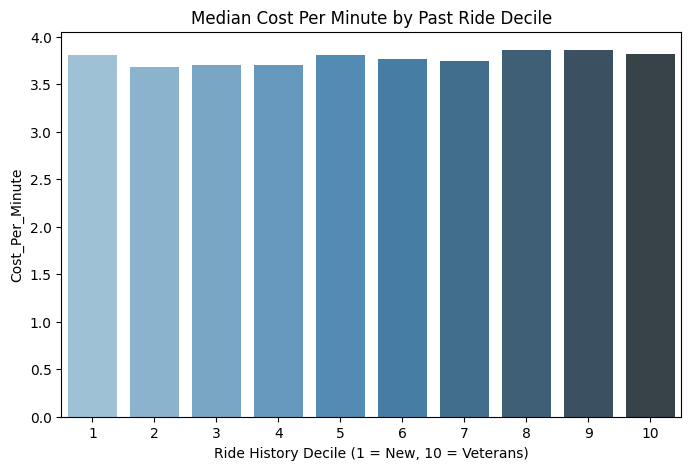

In [35]:
# Bucket users into 10 groups based on ride history
df['Loyalty_Decile'] = pd.qcut(df['Number_of_Past_Rides'], q=10, labels=False, duplicates='drop') + 1

# Check if median cost per minute drops for tenured riders
decile_summary = df.groupby('Loyalty_Decile')['Cost_Per_Minute'].median().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=decile_summary, x='Loyalty_Decile', y='Cost_Per_Minute', palette='Blues_d')
plt.title('Median Cost Per Minute by Past Ride Decile')
plt.xlabel('Ride History Decile (1 = New, 10 = Veterans)')
plt.show()

In [36]:
# 1. Bucket users into 10 groups
df['Loyalty_Decile'] = pd.qcut(df['Number_of_Past_Rides'], q=10, labels=False, duplicates='drop') + 1

# 2. Create the summary table
decile_table = df.groupby('Loyalty_Decile')['Cost_Per_Minute'].agg(
    User_Count='count',
    Median_Cost='median',
    Average_Cost='mean',
    Min_Cost='min',
    Max_Cost='max'
).reset_index()

print("--- Cost Per Minute by Loyalty Decile ---")
print(decile_table)

--- Cost Per Minute by Loyalty Decile ---
   Loyalty_Decile  User_Count  Median_Cost  Average_Cost  Min_Cost  Max_Cost
0               1         108     3.806463      3.864610  2.502595  7.524799
1               2          99     3.682770      3.898182  2.568823  8.889501
2               3          93     3.700243      3.905031  2.532806  8.308139
3               4         101     3.699792      3.853971  2.509614  8.269157
4               5         105     3.810423      3.907005  2.531472  6.662005
5               6          96     3.761968      3.896814  2.509050  7.052115
6               7          99     3.745264      3.934989  2.528163  8.619118
7               8         105     3.859135      3.861662  2.531679  6.738252
8               9          95     3.859642      3.960746  2.506390  8.386836
9              10          99     3.818128      3.825378  2.536460  7.168700


Observation - Loyalty Decile 1 is having the number of new users and after that Decile 10 has the most veteran riders indicating that the median cost per minute is relatively flat.
The dynamic pricing algorithm does not factor in the user tenure. The median cost for the newest rider and the most veteran rider is almost the same.

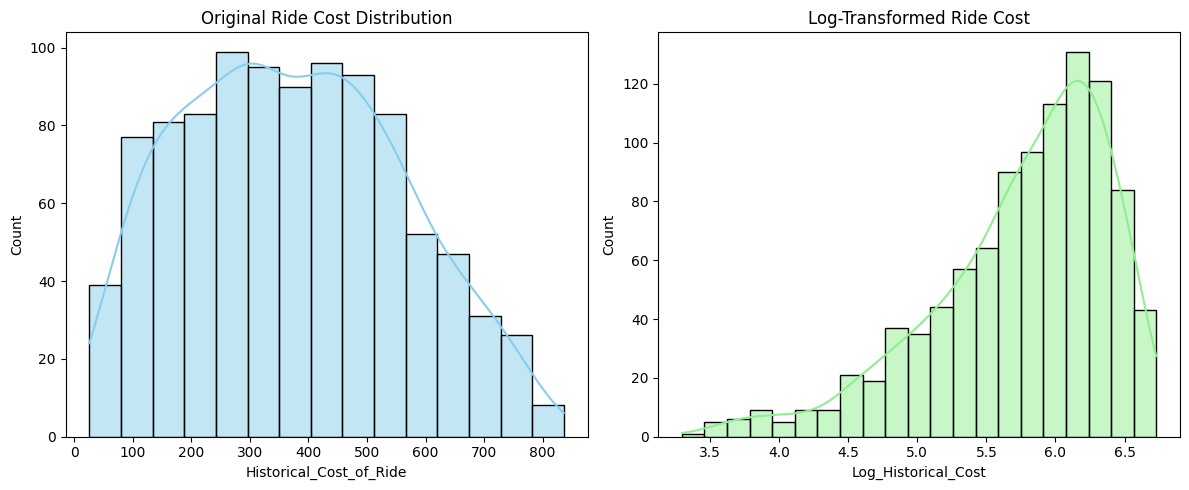

In [37]:
plt.figure(figsize=(12, 5))

# Original Distribution (KDE)
plt.subplot(1, 2, 1)
sns.histplot(df['Historical_Cost_of_Ride'], kde=True, color='skyblue')
plt.title('Original Ride Cost Distribution')

# Log Transformed Distribution
df['Log_Historical_Cost'] = np.log1p(df['Historical_Cost_of_Ride'])
plt.subplot(1, 2, 2)
sns.histplot(df['Log_Historical_Cost'], kde=True, color='lightgreen')
plt.title('Log-Transformed Ride Cost')

plt.tight_layout()
plt.show()

In [38]:
# 1. Apply Log Transformation
df['Log_Historical_Cost'] = np.log1p(df['Historical_Cost_of_Ride'])

# 2. Build a statistical comparison table
distribution_table = pd.DataFrame({
    'Original_Cost': df['Historical_Cost_of_Ride'].describe(),
    'Log_Transformed_Cost': df['Log_Historical_Cost'].describe()
})

# 3. Append skewness to show the normalization effect
distribution_table.loc['skewness'] = [
    df['Historical_Cost_of_Ride'].skew(),
    df['Log_Historical_Cost'].skew()
]

print("--- Target Variable Distribution Summary ---")
print(distribution_table.round(3))

--- Target Variable Distribution Summary ---
          Original_Cost  Log_Transformed_Cost
count          1000.000              1000.000
mean            372.503                 5.755
std             187.159                 0.647
min              25.993                 3.296
25%             221.365                 5.404
50%             362.019                 5.894
75%             510.498                 6.237
max             836.116                 6.730
skewness          0.210                -1.055


Observation - The log transformed cost has less mean value and is negatively skewed meaning that the log transformation over corrects the distribution so, we might not use the log transformed cost. This indicates that it is a balanced dataset as it does not show a heavily positive skew.

# Data Preparation and Train-Test Split

In [39]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. One-Hot Encode categorical variables
# drop_first=True prevents perfect multicollinearity in dummy variables
df_encoded = pd.get_dummies(df, drop_first=True)

# 2. Define Features (X) and Target (y)
# Assuming you dropped the Log_Historical_Cost based on our previous observation
X = df_encoded.drop(columns=['Historical_Cost_of_Ride', 'Log_Historical_Cost'], errors='ignore')
y = df_encoded['Historical_Cost_of_Ride']

# 3. Perform Train-Test Split BEFORE scaling or VIF
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (800, 20)
Testing features shape: (200, 20)


# Multicolinearity Check(VIF)

In [40]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Statsmodels requires a constant to calculate VIF correctly
X_train_vif = add_constant(X_train)

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data["Feature"] = X_train_vif.columns
vif_data["VIF_Score"] = [variance_inflation_factor(X_train_vif.values, i) for i in range(X_train_vif.shape[1])]

# Filter out the constant and sort to find highly collinear features (VIF > 10)
vif_summary = vif_data[vif_data['Feature'] != 'const'].sort_values(by='VIF_Score', ascending=False)

print("--- Variance Inflation Factor (VIF) ---")
print(vif_summary.to_string(index=False))

# Optional: If you see features like 'Number_of_Riders' and 'Demand_to_Supply_Ratio'
# with VIF > 10, drop one of them from X_train and X_test here.

--- Variance Inflation Factor (VIF) ---
                        Feature  VIF_Score
                 Loyalty_Decile 102.057458
           Number_of_Past_Rides 101.942796
              Number_of_Drivers  13.629772
      Ratio_Bucket_(4.31, 17.6]   9.196487
      Ratio_Bucket_(2.75, 4.31]   5.982803
               Number_of_Riders   5.184722
         Demand_to_Supply_Ratio   4.534382
      Ratio_Bucket_(2.03, 2.75]   4.382893
      Ratio_Bucket_(1.54, 2.03]   2.762699
          Time_of_Booking_Night   1.625748
        Time_of_Booking_Morning   1.573915
        Time_of_Booking_Evening   1.573893
                Cost_Per_Minute   1.418107
Customer_Loyalty_Status_Regular   1.410573
 Customer_Loyalty_Status_Silver   1.395523
        Location_Category_Urban   1.384325
     Location_Category_Suburban   1.381115
           Vehicle_Type_Premium   1.255467
         Expected_Ride_Duration   1.200964
                Average_Ratings   1.047180


In [41]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# 1. Base drops (Target variables and the Cost_Per_Minute leakage)
base_drops = ['Historical_Cost_of_Ride', 'Log_Historical_Cost', 'Cost_Per_Minute']

# 2. EDIT THIS LIST MANUALLY: Add one feature at a time and re-run the cell
manual_drops = [
    'Loyalty_Decile'
]

# Drop the columns from your encoded dataframe
X_current = df_encoded.drop(columns=base_drops + manual_drops, errors='ignore')

# 3. Add constant and calculate VIF
X_vif = add_constant(X_current)
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF_Score"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

# 4. Sort and display
vif_summary = vif_data[vif_data['Feature'] != 'const'].sort_values(by='VIF_Score', ascending=False)

print(f"--- VIF Scores (Dropped: {manual_drops}) ---")
print(vif_summary.to_string(index=False))

--- VIF Scores (Dropped: ['Loyalty_Decile']) ---
                        Feature  VIF_Score
              Number_of_Drivers  13.292012
      Ratio_Bucket_(4.31, 17.6]   8.981136
      Ratio_Bucket_(2.75, 4.31]   5.855073
               Number_of_Riders   5.235172
         Demand_to_Supply_Ratio   4.513411
      Ratio_Bucket_(2.03, 2.75]   4.286396
      Ratio_Bucket_(1.54, 2.03]   2.707345
          Time_of_Booking_Night   1.560710
        Time_of_Booking_Morning   1.515745
        Time_of_Booking_Evening   1.511987
Customer_Loyalty_Status_Regular   1.406428
 Customer_Loyalty_Status_Silver   1.406088
     Location_Category_Suburban   1.360439
        Location_Category_Urban   1.359280
                Average_Ratings   1.029388
         Expected_Ride_Duration   1.023820
           Number_of_Past_Rides   1.020603
           Vehicle_Type_Premium   1.011376


In [42]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# 1. Base drops (Target variables and the Cost_Per_Minute leakage)
base_drops = ['Historical_Cost_of_Ride', 'Log_Historical_Cost', 'Cost_Per_Minute']

# 2. EDIT THIS LIST MANUALLY: Add one feature at a time and re-run the cell
manual_drops = [
    'Loyalty_Decile', 'Number_of_Drivers'
]

# Drop the columns from your encoded dataframe
X_current = df_encoded.drop(columns=base_drops + manual_drops, errors='ignore')

# 3. Add constant and calculate VIF
X_vif = add_constant(X_current)
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF_Score"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

# 4. Sort and display
vif_summary = vif_data[vif_data['Feature'] != 'const'].sort_values(by='VIF_Score', ascending=False)

print(f"--- VIF Scores (Dropped: {manual_drops}) ---")
print(vif_summary.to_string(index=False))

--- VIF Scores (Dropped: ['Loyalty_Decile', 'Number_of_Drivers']) ---
                        Feature  VIF_Score
      Ratio_Bucket_(4.31, 17.6]   4.632037
         Demand_to_Supply_Ratio   3.442560
      Ratio_Bucket_(2.75, 4.31]   2.100736
      Ratio_Bucket_(2.03, 2.75]   1.808101
      Ratio_Bucket_(1.54, 2.03]   1.676174
          Time_of_Booking_Night   1.560505
        Time_of_Booking_Morning   1.514777
        Time_of_Booking_Evening   1.511258
Customer_Loyalty_Status_Regular   1.406403
 Customer_Loyalty_Status_Silver   1.399446
     Location_Category_Suburban   1.359910
        Location_Category_Urban   1.358795
               Number_of_Riders   1.103258
                Average_Ratings   1.024444
           Number_of_Past_Rides   1.019129
         Expected_Ride_Duration   1.016948
           Vehicle_Type_Premium   1.011367


In [43]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# 1. Base drops (Target variables and the Cost_Per_Minute leakage)
base_drops = ['Historical_Cost_of_Ride', 'Log_Historical_Cost', 'Cost_Per_Minute']

# 2. EDIT THIS LIST MANUALLY: Add one feature at a time and re-run the cell
manual_drops = [
    'Loyalty_Decile', 'Number_of_Drivers',  'Ratio_Bucket_(1.54, 2.03]',
    'Ratio_Bucket_(2.03, 2.75]',
    'Ratio_Bucket_(2.75, 4.31]',
    'Ratio_Bucket_(4.31, 17.6]'
]

# Drop the columns from your encoded dataframe
X_current = df_encoded.drop(columns=base_drops + manual_drops, errors='ignore')

# 3. Add constant and calculate VIF
X_vif = add_constant(X_current)
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF_Score"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

# 4. Sort and display
vif_summary = vif_data[vif_data['Feature'] != 'const'].sort_values(by='VIF_Score', ascending=False)

print(f"--- VIF Scores (Dropped: {manual_drops}) ---")
print(vif_summary.to_string(index=False))

--- VIF Scores (Dropped: ['Loyalty_Decile', 'Number_of_Drivers', 'Ratio_Bucket_(1.54, 2.03]', 'Ratio_Bucket_(2.03, 2.75]', 'Ratio_Bucket_(2.75, 4.31]', 'Ratio_Bucket_(4.31, 17.6]']) ---
                        Feature  VIF_Score
          Time_of_Booking_Night   1.558829
        Time_of_Booking_Morning   1.510954
        Time_of_Booking_Evening   1.506682
Customer_Loyalty_Status_Regular   1.402378
 Customer_Loyalty_Status_Silver   1.390266
     Location_Category_Suburban   1.356909
        Location_Category_Urban   1.356788
         Demand_to_Supply_Ratio   1.030407
               Number_of_Riders   1.019584
           Number_of_Past_Rides   1.018355
                Average_Ratings   1.012734
         Expected_Ride_Duration   1.009063
           Vehicle_Type_Premium   1.008972


# Model Training and Benchmarking

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Define final X and y using your successful manual drops
columns_to_drop = [
    'Historical_Cost_of_Ride', 'Log_Historical_Cost', 'Cost_Per_Minute',
    'Loyalty_Decile', 'Number_of_Drivers',
    'Ratio_Bucket_(1.54, 2.03]', 'Ratio_Bucket_(2.03, 2.75]',
    'Ratio_Bucket_(2.75, 4.31]', 'Ratio_Bucket_(4.31, 17.6]'
]

X = df_encoded.drop(columns=columns_to_drop, errors='ignore')
y = df_encoded['Historical_Cost_of_Ride']

# 2. Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Feature Scaling (Fit on Train, Transform on Train & Test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame to preserve column names for feature importance later
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

# 4. Initialize Models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

results = []

# 5. Train and Benchmark
for name, model in models.items():
    # Train
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)

    # Evaluate
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "RMSE": round(rmse, 2),
        "R-Squared": round(r2, 4)
    })

# 6. Display Results
benchmark_df = pd.DataFrame(results).sort_values(by="R-Squared", ascending=False)
print("--- Model Benchmarking Results ---")
print(benchmark_df.to_markdown(index=False))

--- Model Benchmarking Results ---
| Model             |   RMSE |   R-Squared |
|:------------------|-------:|------------:|
| Linear Regression |  67.6  |      0.8747 |
| Random Forest     |  74.45 |      0.848  |
| XGBoost           |  76.43 |      0.8398 |


# Analysis of Predicted and Actual Prices

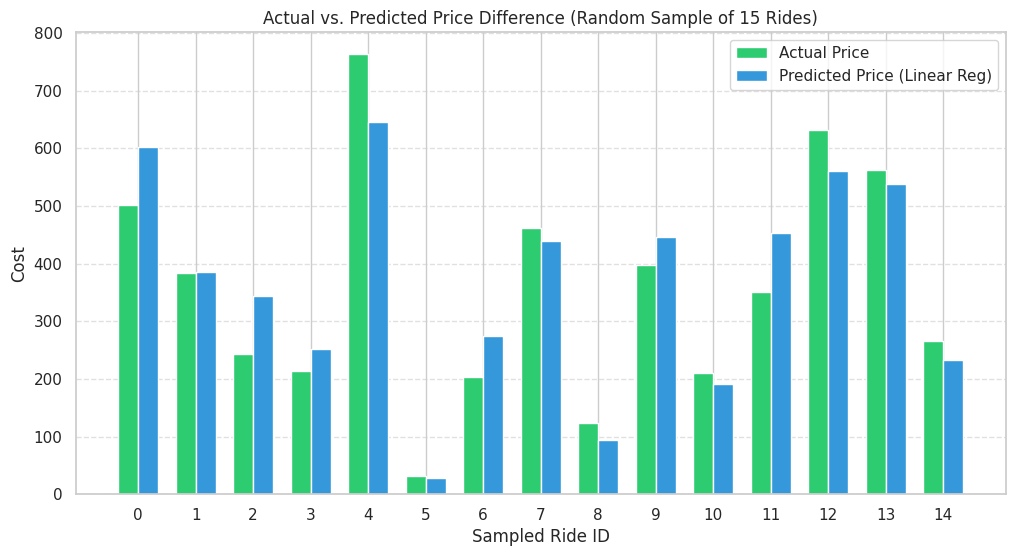

--- TABLE 1: Top 5 BEST Predictions (Smallest Difference) ---
|   Actual_Price |   Predicted_Price |   Difference_(₹) |   Error_(%) |
|---------------:|------------------:|-----------------:|------------:|
|         237.77 |            237.61 |             0.16 |        0.07 |
|         111.11 |            110.92 |             0.19 |        0.17 |
|         585    |            585.31 |            -0.32 |        0.05 |
|         407.55 |            407.97 |            -0.42 |        0.1  |
|          40.44 |             39.58 |             0.87 |        2.14 |


--- TABLE 2: Top 5 WORST Predictions (Largest Difference) ---
|   Actual_Price |   Predicted_Price |   Difference_(₹) |   Error_(%) |
|---------------:|------------------:|-----------------:|------------:|
|         398.32 |            562.59 |          -164.27 |       41.24 |
|         406.56 |            570.78 |          -164.22 |       40.39 |
|         836.12 |            677.99 |           158.13 |       18.91 |
|         

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a detailed DataFrame of the differences using the winning model
lr_pred = models["Linear Regression"].predict(X_test_scaled)

diff_df = pd.DataFrame({
    'Actual_Price': y_test.values,
    'Predicted_Price': lr_pred,
    'Difference_(₹)': y_test.values - lr_pred
})

# Calculate Absolute Difference and % Error for business context
diff_df['Abs_Difference'] = diff_df['Difference_(₹)'].abs()
diff_df['Error_(%)'] = (diff_df['Abs_Difference'] / diff_df['Actual_Price']) * 100

# ---------------------------------------------------------
# THE GRAPH: Side-by-Side Bar Chart for a 15-Ride Sample
# ---------------------------------------------------------
sample_df = diff_df.sample(n=15, random_state=42).reset_index(drop=True)

plt.figure(figsize=(12, 6))
x = np.arange(len(sample_df))
width = 0.35

plt.bar(x - width/2, sample_df['Actual_Price'], width, label='Actual Price', color='#2ecc71')
plt.bar(x + width/2, sample_df['Predicted_Price'], width, label='Predicted Price (Linear Reg)', color='#3498db')

plt.title("Actual vs. Predicted Price Difference (Random Sample of 15 Rides)")
plt.xlabel("Sampled Ride ID")
plt.ylabel("Cost")
plt.xticks(x, sample_df.index)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# ---------------------------------------------------------
# THE TABLES: Best vs Worst Predictions
# ---------------------------------------------------------
# Top 5 most accurate predictions
best_preds = diff_df.sort_values(by='Abs_Difference', ascending=True).head(5)
best_preds = best_preds.drop(columns=['Abs_Difference'])

# Top 5 worst predictions
worst_preds = diff_df.sort_values(by='Abs_Difference', ascending=False).head(5)
worst_preds = worst_preds.drop(columns=['Abs_Difference'])

print("--- TABLE 1: Top 5 BEST Predictions (Smallest Difference) ---")
print(best_preds.round(2).to_markdown(index=False))
print("\n")

print("--- TABLE 2: Top 5 WORST Predictions (Largest Difference) ---")
print(worst_preds.round(2).to_markdown(index=False))

Linear Regression model reverse-engineers core pricing formula for all pricing scales. There are some rare extreme errors where anomalies are there in predicted price that might be due to promotional discounts where in user uses a coupon and gets price of cab at low cost or the predicted price might be high due to severe traffic if the time of the ride takes longer.

/tmp/ipykernel_4441/100127398.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=rf_importance, palette='viridis')


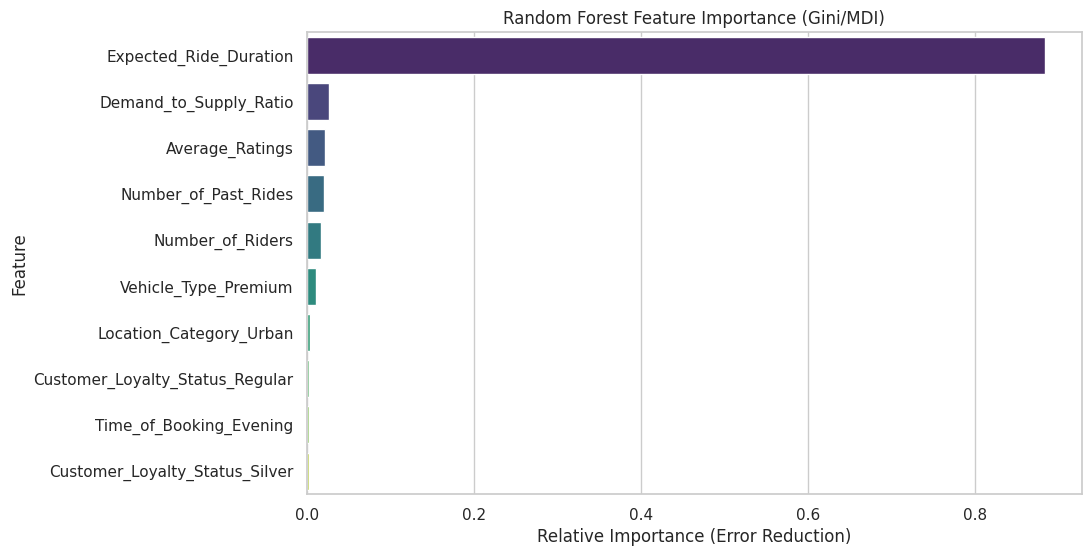

In [48]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the trained Random Forest model
rf_model = models["Random Forest"]

# Map importances to feature names
rf_importance = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Importance': rf_model.feature_importances_
})

# Sort and take the top 10
rf_importance = rf_importance.sort_values(by='Importance', ascending=False).head(10)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=rf_importance, palette='viridis')
plt.title("Random Forest Feature Importance (Gini/MDI)")
plt.xlabel("Relative Importance (Error Reduction)")
plt.ylabel("Feature")
plt.show()

In [53]:
print("--- Random Forest Feature Importance (Top 10) ---")
print(rf_importance.to_markdown(index=False))
print("\n")

--- Random Forest Feature Importance (Top 10) ---
| Feature                         |   Importance |
|:--------------------------------|-------------:|
| Expected_Ride_Duration          |   0.883571   |
| Demand_to_Supply_Ratio          |   0.0262394  |
| Average_Ratings                 |   0.0214151  |
| Number_of_Past_Rides            |   0.0207458  |
| Number_of_Riders                |   0.0170584  |
| Vehicle_Type_Premium            |   0.0113455  |
| Location_Category_Urban         |   0.00352832 |
| Customer_Loyalty_Status_Regular |   0.00310037 |
| Time_of_Booking_Evening         |   0.00289646 |
| Customer_Loyalty_Status_Silver  |   0.00269395 |




Expected ride duration contributes the most to the pricing model establishing the base fare. Features like Demand to Supply Ratio and Vehicle Type act as surge multipliers adjusting baseline.

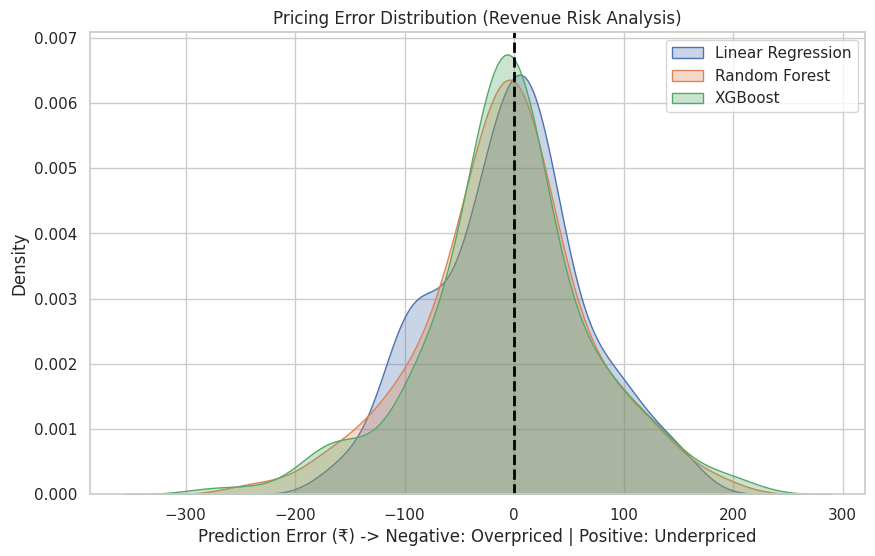

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals (Actual - Predicted)
# Positive = Underpriced (Lost Margin), Negative = Overpriced (Lost Conversion)
residuals = {
    "Linear Regression": y_test - models["Linear Regression"].predict(X_test_scaled),
    "Random Forest": y_test - models["Random Forest"].predict(X_test_scaled),
    "XGBoost": y_test - models["XGBoost"].predict(X_test_scaled)  # Updated key
}

plt.figure(figsize=(10, 6))
for model_name, res in residuals.items():
    sns.kdeplot(res, fill=True, alpha=0.3, label=model_name)

plt.axvline(0, color='black', linestyle='--', linewidth=2)
plt.title("Pricing Error Distribution (Revenue Risk Analysis)")
plt.xlabel("Prediction Error (₹) -> Negative: Overpriced | Positive: Underpriced")
plt.ylabel("Density")
plt.legend()
plt.show()

In [63]:
residual_stats = []
for name, res in residuals.items():
    residual_stats.append({
        "Model": name,
        "Average Bias (₹)": round(res.mean(), 2),
        "Max Overprice (₹)": round(res.min(), 2),  # Negative residual = overpricing
        "Max Underprice (₹)": round(res.max(), 2)  # Positive residual = underpricing
    })

print("--- 3. Error & Revenue Risk Summary ---")
print(pd.DataFrame(residual_stats).to_markdown(index=False))
print("\n")

--- 3. Error & Revenue Risk Summary ---
| Model             |   Average Bias (₹) |   Max Overprice (₹) |   Max Underprice (₹) |
|:------------------|-------------------:|--------------------:|---------------------:|
| Linear Regression |              -4.36 |             -164.27 |               158.13 |
| Random Forest     |              -8.7  |             -244.55 |               191.46 |
| XGBoost           |              -6.59 |             -275.47 |               209.12 |




If revenue risk analysis is performed, Linear Regression is the most stable model financially because it maintains the lowest average bias and tightly caps worst-case pricing errors.

If XGBoost makes a bad prediction, then it prices the ride by Rs. 275 causing the ride to get cancelled.

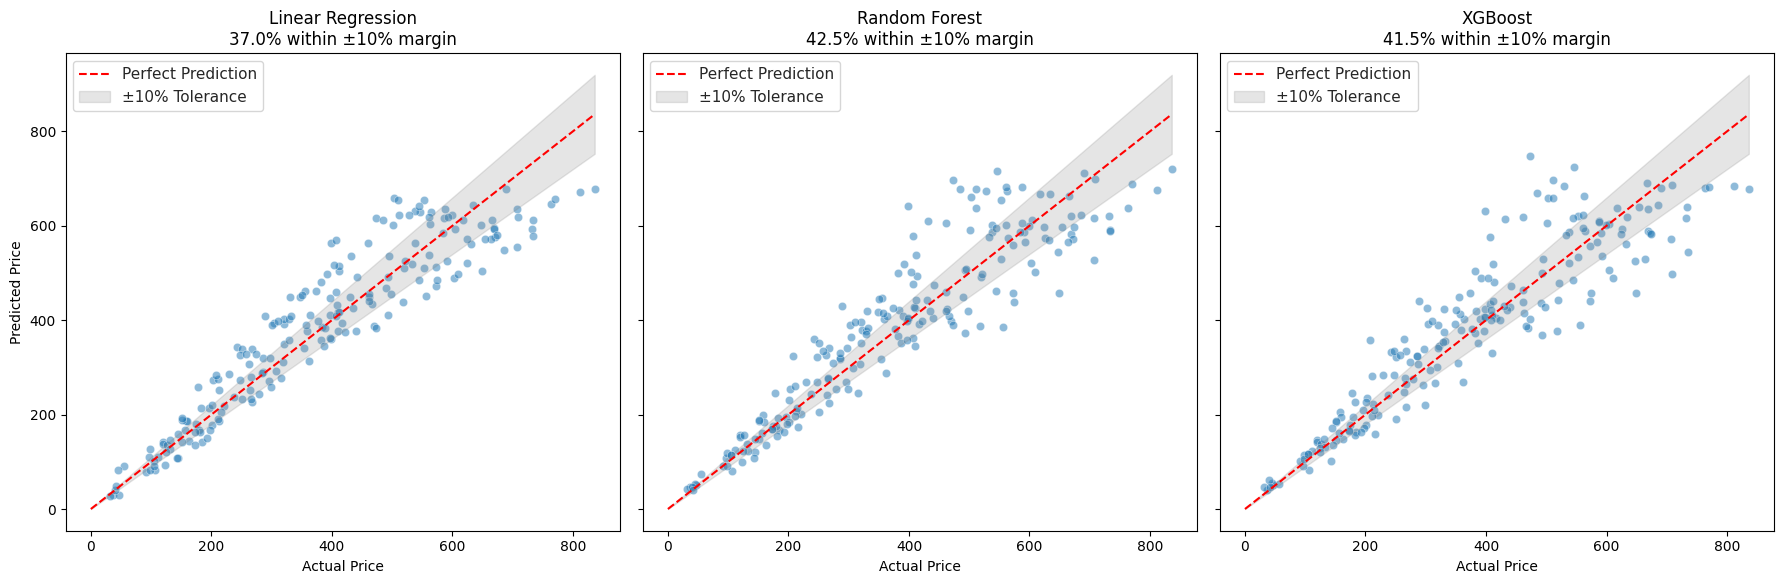

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
sns.set_theme(style="whitegrid")

for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test_scaled)
    ax = axes[idx]

    # Scatter plot of predictions
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, ax=ax)

    # Perfect prediction line
    max_val = y_test.max()
    ax.plot([0, max_val], [0, max_val], color='red', linestyle='--', label='Perfect Prediction')

    # +/- 10% Tolerance Bands
    ax.fill_between([0, max_val], [0, max_val*0.9], [0, max_val*1.1], color='gray', alpha=0.2, label='±10% Tolerance')

    # Calculate % in tolerance
    in_tol = np.mean((y_pred >= y_test * 0.9) & (y_pred <= y_test * 1.1)) * 100

    ax.set_title(f"{name}\n{in_tol:.1f}% within ±10% margin")
    ax.set_xlabel("Actual Price")
    if idx == 0: ax.set_ylabel("Predicted Price")
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [55]:
tolerance_results = []
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    # Calculate % in tolerance
    in_tol = np.mean((y_pred >= y_test * 0.9) & (y_pred <= y_test * 1.1)) * 100
    tolerance_results.append({
        "Model": name,
        "Within ±10% Margin (%)": round(in_tol, 2)
    })

print("--- 2. Pricing Guardrails (±10% Tolerance) ---")
print(pd.DataFrame(tolerance_results).to_markdown(index=False))
print("\n")

--- 2. Pricing Guardrails (±10% Tolerance) ---
| Model             |   Within ±10% Margin (%) |
|:------------------|-------------------------:|
| Linear Regression |                     37   |
| Random Forest     |                     42.5 |
| XGBoost           |                     41.5 |




While tree models have a slightly higher volume of predictions, they suffer from catastrophic outlier errors. Linear Regression has a slightly more variance for proper operational stability.

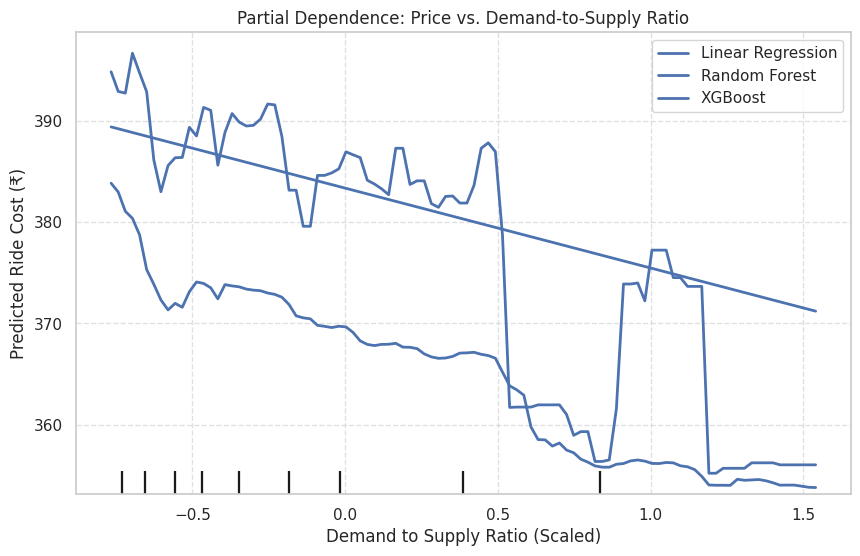

In [64]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))
display = None

# Plot the PDP for all three models on the same axis
for name, model in models.items():
    if display is None:
        # 1. For the first model, draw on the main 'ax' and save the display object
        display = PartialDependenceDisplay.from_estimator(
            model, X_test_scaled, features=['Demand_to_Supply_Ratio'],
            ax=ax, line_kw={"label": name, "linewidth": 2}
        )
    else:
        # 2. For the remaining models, map them onto the existing display axes
        PartialDependenceDisplay.from_estimator(
            model, X_test_scaled, features=['Demand_to_Supply_Ratio'],
            ax=display.axes_, line_kw={"label": name, "linewidth": 2}
        )

plt.title("Partial Dependence: Price vs. Demand-to-Supply Ratio")
plt.xlabel("Demand to Supply Ratio (Scaled)")
plt.ylabel("Predicted Ride Cost (₹)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [57]:
from sklearn.inspection import partial_dependence
import pandas as pd

pdp_results = {}
grid_values = None

for name, model in models.items():
    # Calculate partial dependence data at 10 evenly spaced points
    pdp_data = partial_dependence(
        model,
        X_test_scaled,
        features=['Demand_to_Supply_Ratio'],
        grid_resolution=10 # Limits output to 10 rows for a clean table
    )

    # Capture the x-axis (Demand points) on the first loop
    if grid_values is None:
        grid_values = pdp_data['grid_values'][0]

    # Capture the y-axis (Predicted Price) for each model
    pdp_results[name] = pdp_data['average'][0]

# Combine into a single DataFrame
pdp_table = pd.DataFrame(pdp_results)
pdp_table.insert(0, 'Demand_to_Supply_Ratio (Scaled)', grid_values)

print("--- Partial Dependence Summary (Price vs. Demand) ---")
print(pdp_table.round(2).to_markdown(index=False))

--- Partial Dependence Summary (Price vs. Demand) ---
|   Demand_to_Supply_Ratio (Scaled) |   Linear Regression |   Random Forest |   XGBoost |
|----------------------------------:|--------------------:|----------------:|----------:|
|                             -0.77 |              389.38 |          383.83 |    394.81 |
|                             -0.51 |              387.36 |          373.13 |    389.35 |
|                             -0.25 |              385.34 |          373    |    391.64 |
|                              0    |              383.32 |          369.66 |    386.93 |
|                              0.26 |              381.31 |          367    |    384.07 |
|                              0.51 |              379.29 |          365.21 |    378.65 |
|                              0.77 |              377.27 |          356.63 |    359.34 |
|                              1.03 |              375.25 |          356.19 |    377.23 |
|                              1.28 |         

Partial dependence analysis shows Linear Regression model scaling prices proportionally and predictably against demand.

The tree-based architectures exhibit non-monotonic prices. For random forest, it drops price by 10 rupees in first step but then completely flatlines between -0.51 and -0.25.

For XGBoost, at 0.77, it drops price upto 359.34 but as demand increases, the price goes upto 377.23

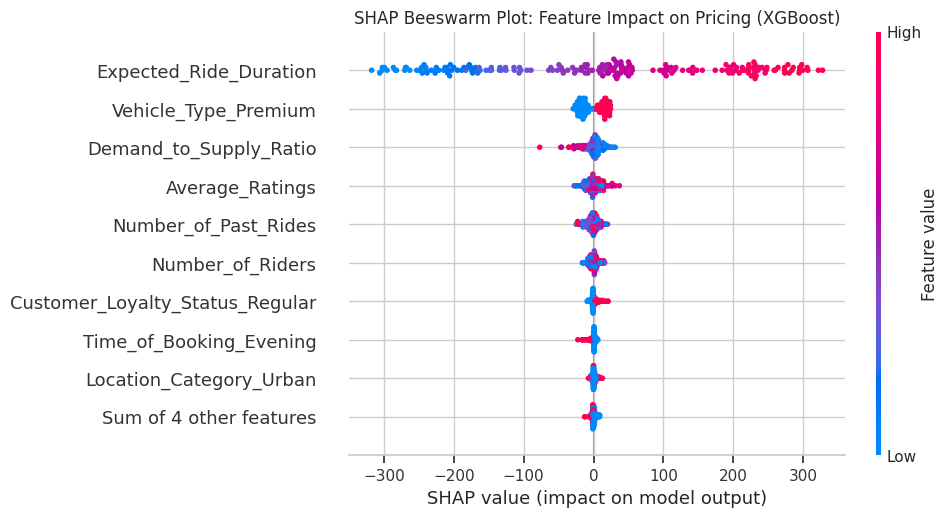

In [50]:
# !pip install shap
import shap

# Initialize the SHAP explainer on the XGBoost model
xgb_model = models["XGBoost"]
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values for the test set
shap_values = explainer(X_test_scaled)

# Generate the Beeswarm plot
plt.figure(figsize=(10, 6))
plt.title("SHAP Beeswarm Plot: Feature Impact on Pricing (XGBoost)")
shap.plots.beeswarm(shap_values, max_display=10)

In [65]:
shap_summary = pd.DataFrame({
    'Feature': X_test_scaled.columns,
    'Mean_Abs_SHAP_Value': np.abs(shap_values.values).mean(axis=0)
}).sort_values(by='Mean_Abs_SHAP_Value', ascending=False).head(10)

print("--- 4. XGBoost SHAP Importance (Average Rupees Impact) ---")
print(shap_summary.round(4).to_markdown(index=False))

--- 4. XGBoost SHAP Importance (Average Rupees Impact) ---
| Feature                         |   Mean_Abs_SHAP_Value |
|:--------------------------------|----------------------:|
| Expected_Ride_Duration          |              152.149  |
| Vehicle_Type_Premium            |               16.0178 |
| Demand_to_Supply_Ratio          |                8.5895 |
| Average_Ratings                 |                7.9974 |
| Number_of_Past_Rides            |                5.6407 |
| Number_of_Riders                |                4.0418 |
| Customer_Loyalty_Status_Regular |                2.4485 |
| Time_of_Booking_Evening         |                2.2685 |
| Location_Category_Urban         |                1.6076 |
| Location_Category_Suburban      |                0.9618 |


SHAP Feature importance translates the feature importance into direct monetary fact.

Expected Ride duration is for the core base fare which can alter price by 152 per trip while Premium Vehicle Type adjusts fare by average of 16.